<a href="https://colab.research.google.com/github/Brunolms11/Calc_Numerico/blob/main/ATividade_19_10_CN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

A = np.array([[10.0, -1.0, 2.0],
              [-1.0, 11.0, -1.0],
              [2.0, -1.0, 10.0]])
b = np.array([6.0, 22.0, -10.0])

x_ant = np.zeros(3)
tolerancia = 1e-5
max_iter = 100

print(f"k=0: x = {x_ant}")

historico = [list(x_ant)]
erros = []

for k in range(1, max_iter + 1):
    x_novo = np.copy(x_ant)


    x_novo[0] = (b[0] - A[0, 1]*x_ant[1] - A[0, 2]*x_ant[2]) / A[0, 0]
    x_novo[1] = (b[1] - A[1, 0]*x_novo[0] - A[1, 2]*x_ant[2]) / A[1, 1]
    x_novo[2] = (b[2] - A[2, 0]*x_novo[0] - A[2, 1]*x_novo[1]) / A[2, 2]


    erro = np.max(np.abs(x_novo - x_ant))
    erros.append(erro)
    historico.append(list(x_novo))

    print(f"Iteração {k}: x={x_novo[0]:.6f}, y={x_novo[1]:.6f}, z={x_novo[2]:.6f} | Erro={erro:.2e}")

    if erro < tolerancia:
        print(f"\nConvergência atingida na iteração {k}!")
        break

    x_ant = np.copy(x_novo)

k=0: x = [0. 0. 0.]
Iteração 1: x=0.600000, y=2.054545, z=-0.914545 | Erro=2.05e+00
Iteração 2: x=0.988364, y=2.006711, z=-0.997002 | Erro=3.88e-01
Iteração 3: x=1.000071, y=2.000279, z=-0.999986 | Erro=1.17e-02
Iteração 4: x=1.000025, y=2.000004, z=-1.000005 | Erro=2.76e-04
Iteração 5: x=1.000001, y=2.000000, z=-1.000000 | Erro=2.39e-05
Iteração 6: x=1.000000, y=2.000000, z=-1.000000 | Erro=1.26e-06

Convergência atingida na iteração 6!


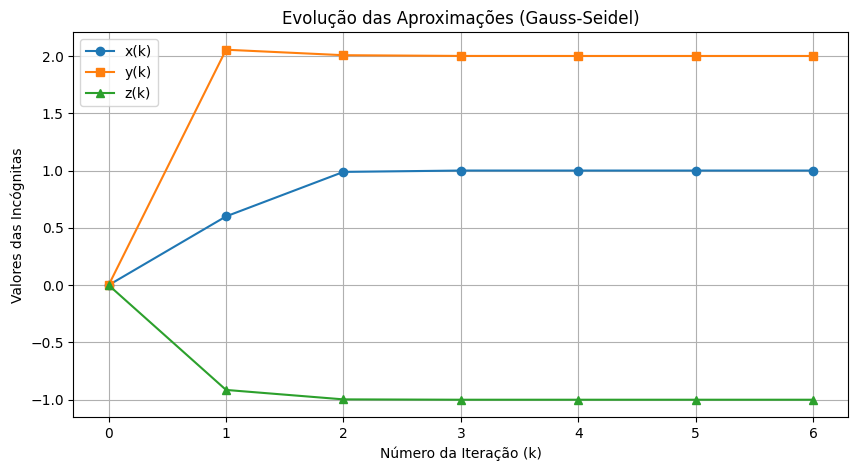

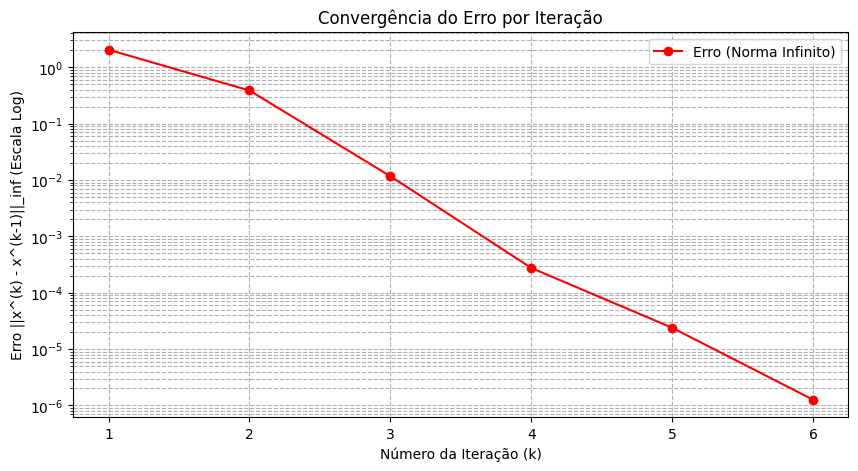

In [2]:
import matplotlib.pyplot as plt

hist_arr = np.array(historico)
iteracoes = range(len(hist_arr))

plt.figure(figsize=(10, 5))
plt.plot(iteracoes, hist_arr[:, 0], 'o-', label='x(k)')
plt.plot(iteracoes, hist_arr[:, 1], 's-', label='y(k)')
plt.plot(iteracoes, hist_arr[:, 2], '^-', label='z(k)')
plt.xlabel('Número da Iteração (k)')
plt.ylabel('Valores das Incógnitas')
plt.title('Evolução das Aproximações (Gauss-Seidel)')
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.semilogy(range(1, len(erros) + 1), erros, 'ro-', label='Erro (Norma Infinito)')
plt.xlabel('Número da Iteração (k)')
plt.ylabel('Erro ||x^(k) - x^(k-1)||_inf (Escala Log)')
plt.title('Convergência do Erro por Iteração')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()